# CsI(Tl)–SiPM：PID 带宽差异、噪声分解与原生 Geant4 检验

日期：2026-10-29。接续 [PID 笔记](codex_0001_csi_geant4_pid.ipynb)。

本轮问题：**PID 带宽是否来自噪声，能否使模拟与实测的带宽更接近？**
这里把“基线电子学噪声”“光子/雪崩统计”“信号期间的相关起伏”分开讨论。
实测数据没有逐事件粒子真值，不能把所有 Am 波形直接称为 α，或把测量分布唯一归因为某种噪声。
Geant4 中仍保留 Am 的 α、γ 和衰变电子。

本轮新增噪声关闭对照、训练段联合协方差拟合、**56000 个新随机种子母衰变**及对应原生 C++ 数字化对照。
旧波形/PID 结果不覆盖；拟合候选与验证结果保存于独立目录。


In [1]:
from pathlib import Path
import json, sys, hashlib
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/pid_bandwidth_20261029'
def read(p): return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
diagnosis=read(OUT/'diagnosis.json'); fit=read(OUT/'covariance_fit/fit.json')
validation=read(OUT/'validation/assessment.json'); protocol=read(OUT/'validation/protocol.json')
decision=read(OUT/'decision.json')
methods=validation['methods']; labels=['长短门比','负平均时间','冻结 PCA']
print('Project:',PROJECT)
print('Python / NumPy:',sys.version.split()[0],np.__version__)
display(Markdown(decision['summary_zh']))

Project: /media/sf_works/SiPM
Python / NumPy: 3.13.5 2.5.4


**已改善 Am 的带宽差异；尚未实现所有 PID 方法、所有采集段一致。基线噪声不是唯一来源。**

下表为实验最后20%对应的、按固定Q箱汇总的模拟/实测IQR比值，1为相同宽度：

| run | 旧QDC | 新QDC | 新负平均时间 | 新PCA |
|---|---|---|---|---|
| 3 | 1.416 | 1.468 | 1.059 | 1.245 |
| 12 | 0.726 | 0.881 | 0.760 | 0.823 |
| 18 | 0.811 | 0.882 | 0.925 | 0.926 |

Co 的偏宽仍在；Am run12 的平均时间带仍偏窄。统计区间与逐箱结果见后文。
本轮保留噪声修正为条件候选，未将其宣称为全面验证的探测器响应，也未覆盖默认配置或旧结果。

## 1. 为什么不能只增加基线 RMS

对长短门比 $R=Q_s/Q_l$，一阶传播为

$$\operatorname{Var}(R)\simeq\frac{\operatorname{Var}(Q_s)+R^2\operatorname{Var}(Q_l)-2R\operatorname{Cov}(Q_s,Q_l)}{Q_l^2}.$$

长、短门共享采样点；因此噪声的时间相关性及两门协方差与噪声 RMS 同样关键。
有限光电子数、雪崩电荷起伏、事件间发光/收光变化，以及 t10 对齐和基线估计也会使带变宽。
相同基线 RMS 不保证相同 PID 带宽。

本轮在同一旧母事件和同一原始 Q 箱上关闭附加信号残差，保留所有光学历史、原生 SiPM 雪崩与基线噪声。
逐采样拆成 $S+B+N+q$：原生信号、基线电子学、信号残差、ADC 量化。
对每个分量分别扣除前128点均值，并使用完整波形的原 anchor。
对三个比值型分数作**精确代数协方差分解**，包含所有交叉项。

图中“原生信号”仍包括光子/雪崩统计、几何以及含噪 anchor 的影响，不能全归为材料本征涨落；
固定选择产生的交叉项可能为负。分量对角项的比例不是互斥的因果贡献，单项可能超过100%。


|run|方法|原生信号|基线电子学|信号残差|量化|交叉项|
|---|---|---|---|---|---|---|
|3|长短门比|94.12%|1.30%|6.53%|0.00%|-1.95%|
|3|负平均时间|97.02%|4.67%|5.41%|0.01%|-7.10%|
|3|冻结 PCA|94.39%|1.88%|5.75%|0.00%|-2.02%|
|12|长短门比|73.19%|0.30%|41.71%|0.00%|-15.21%|
|12|负平均时间|76.38%|1.04%|35.98%|0.00%|-13.40%|
|12|冻结 PCA|74.46%|0.45%|42.41%|0.00%|-17.33%|
|18|长短门比|86.47%|0.89%|21.20%|0.00%|-8.56%|
|18|负平均时间|89.98%|2.95%|17.66%|0.00%|-10.59%|
|18|冻结 PCA|87.73%|1.30%|20.65%|0.00%|-9.68%|

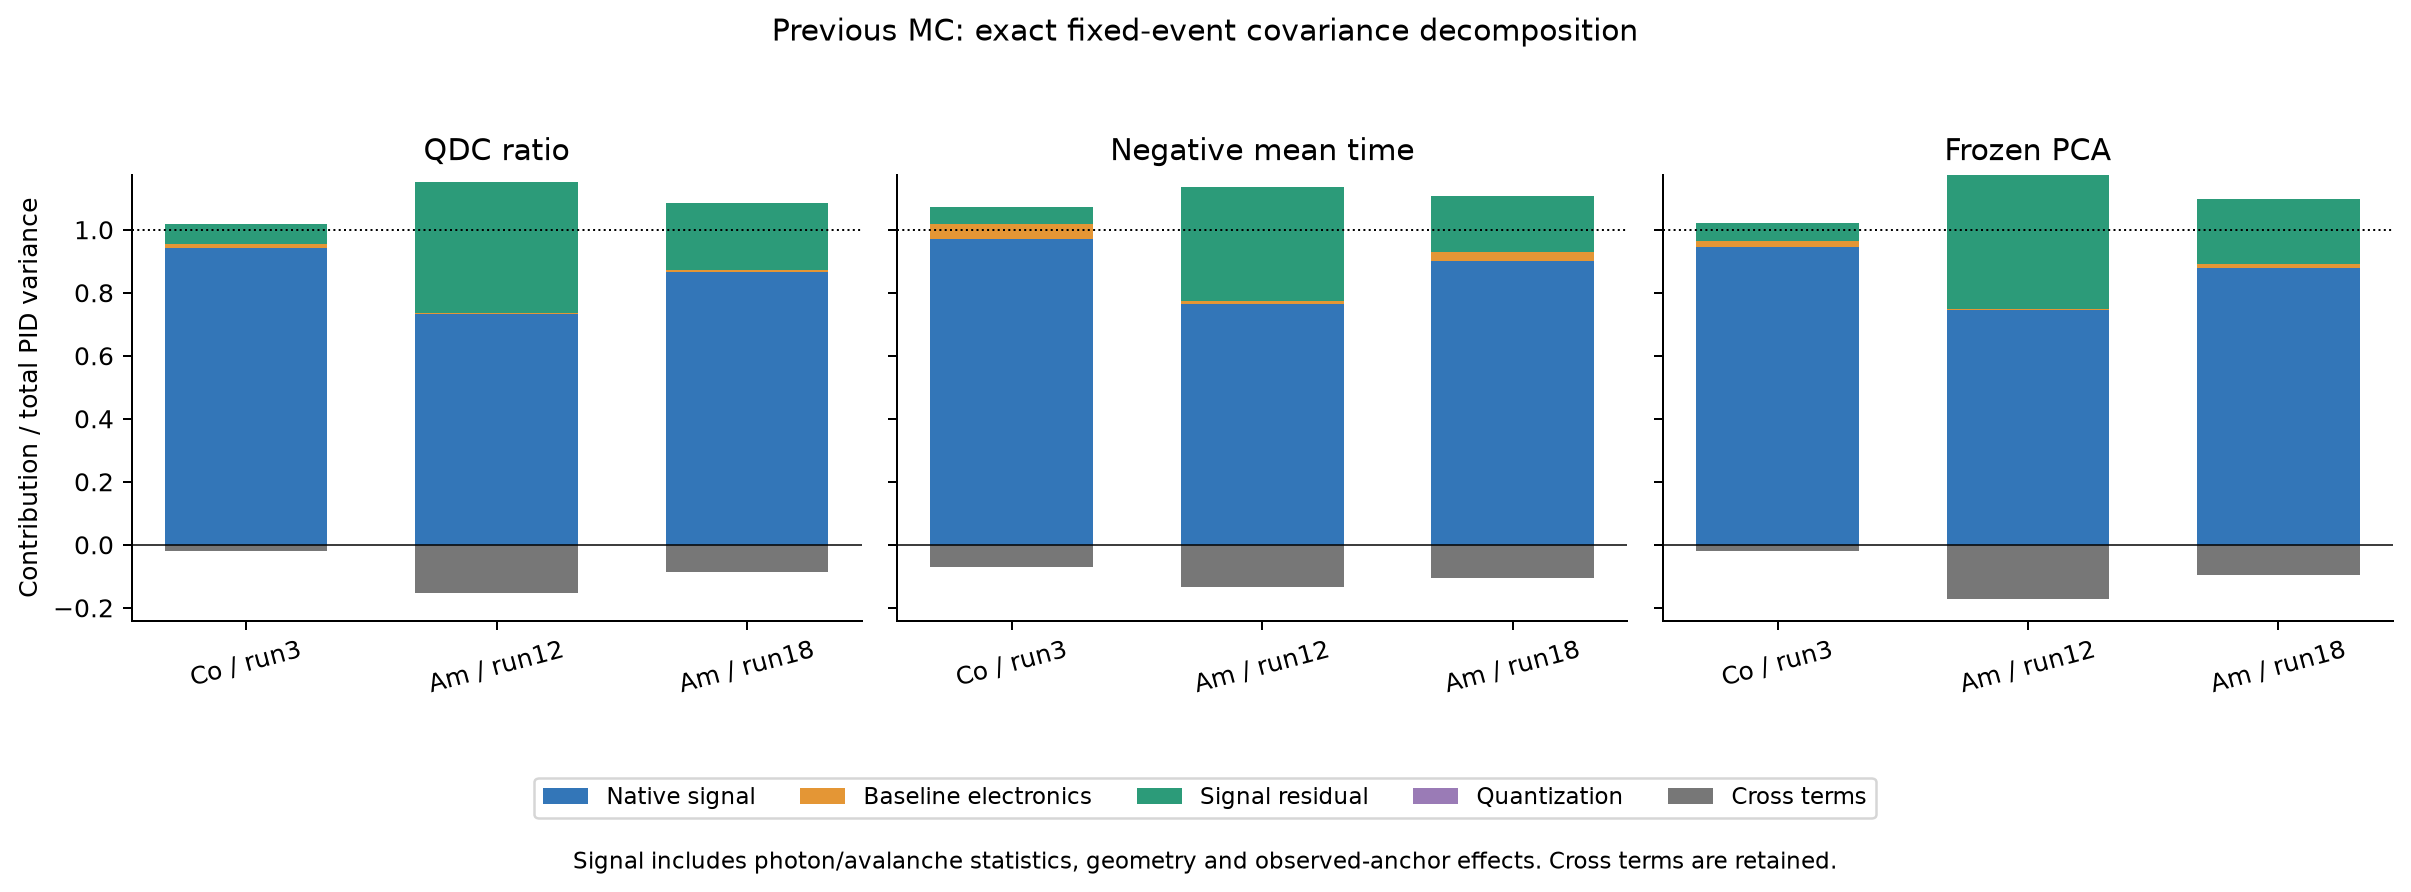

In [2]:
rows=[]
for run in [3,12,18]:
    support=fit['states'][f'run{run}']['support_bins']
    cov=np.mean([np.asarray(x['covariances']) for x in diagnosis['MC'][f'run{run}']['decomposition'] if x['bin'] in support],axis=0)
    for j,label in enumerate(labels):
        v=cov[j]; total=v.sum()
        fractions=np.r_[np.diag(v),total-np.trace(v)]/total*100
        rows.append([run,label,*[f'{x:.2f}%' for x in fractions]])
display(Markdown(table(['run','方法','原生信号','基线电子学','信号残差','量化','交叉项'],rows)))
display(Image(filename=str(OUT/'figures/pid_noise_contributions.png')))

## 2. 基线敏感性与训练方式

另用严格位于触发前的 `[anchor−192, anchor−64)` 共128点估计基线，对相同 ID、相同原 anchor 和原 Q 箱重算 PID。
这项敏感性检查没有改变正式分析的基线方法，也没有通过重新筛选事件隐藏带尾。
实验主带诊断沿用原有0.4积分比界线（Co高侧、Am低侧），并另存界线外事件数；这不是实验粒子标签。

已有附加信号噪声使用400 ns局部窗和50/102/202 ns滤波涨落约束，微秒尺度的积分协方差没有得到充分约束。
本轮只使用各 run 的 **first60**，以三个 PID 的完整3×3协方差和三个短尺度涨落均值共同约束噪声频谱。
实验协方差在各 Q 箱按中位数±3×IQR/1.349温和截尾，模拟基础协方差保留；只取有足够 MC 和实验支持的箱。
各箱等权，避免 Q 谱形差异冒充带宽变化。

旧频谱、白噪声和20/60/150/400/1000/2500 ns指数相关核提供非负频谱分量；非负最小二乘后合成为1025点 FIR，
由已有原生 C++ `SignalDependentNoise` 执行：方差随瞬时无噪信号强度变化，零信号时附加项为零。
未改变平均发光/光学参数、PDE、SiPM 增益、RC、基线噪声或事件方差离散度；没有直接给 PID 分数加随机数。

**不同 run 的频谱仍是经验采集状态，不是证明了同位素相关噪声。** 同一 run12 响应也应用于两种源，用于共同读出 PID 检查。
2500 ns 是有限 FIR 分量的参数标签，不能把它当成测得的真实相关时间或电路时间常数。


|run|训练支持Q箱|非负频谱分量功率|合成 κ|
|---|---|---|---|
|3|0,1,2,3,4,5|white: 0.019472, exponential_20ns: 0.18882|0.208246|
|12|0,1,2|previous_spectrum: 1.4301, exponential_150ns: 0.12862, exponential_400ns: 0.41888, exponential_2500ns: 0.049156|1.9993|
|18|0,1,2|previous_spectrum: 0.75533, exponential_20ns: 0.0010904, exponential_2500ns: 0.22722|0.944317|

|run|段|条数|主带外|基线RMS中位数|两种基线差的SD|
|---|---|---|---|---|---|
|3|first60|2450|27|3.353|2.107|
|3|last20|826|5|3.317|2.112|
|12|first60|1547|0|3.167|1.740|
|12|last20|407|0|5.677|6.218|
|18|first60|3000|0|4.965|5.272|
|18|last20|3000|0|4.950|5.314|

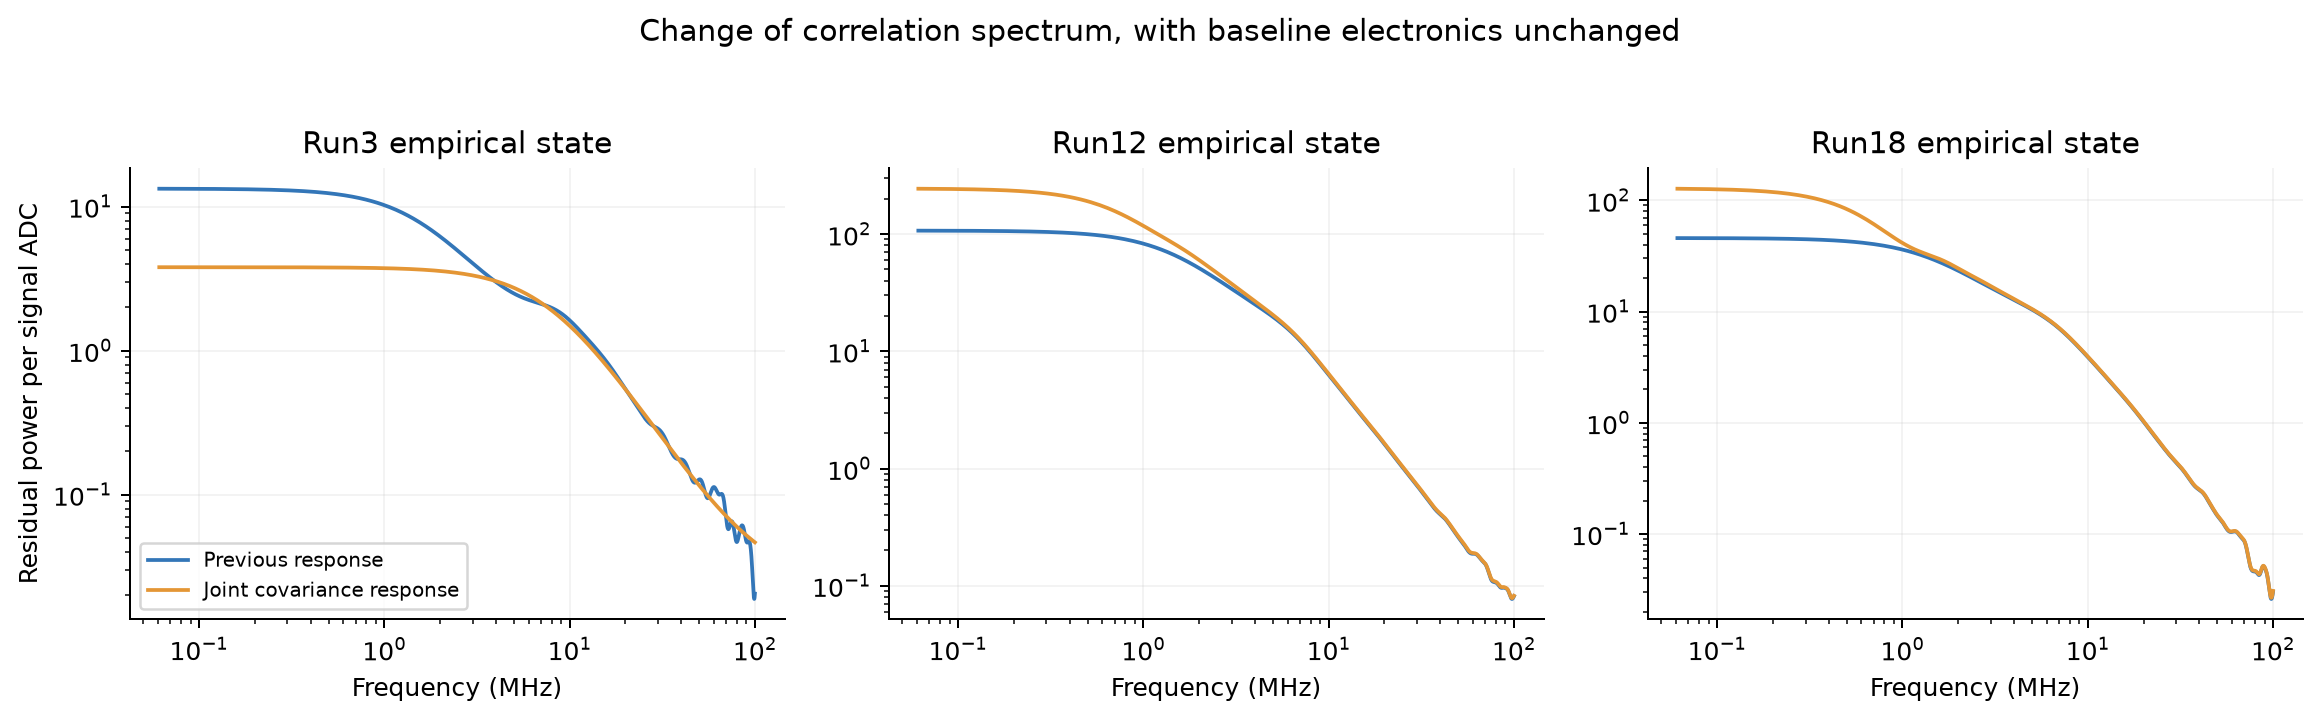

In [3]:
rows=[]
for run in [3,12,18]:
    r=fit['states'][f'run{run}']
    active=', '.join(f'{k}: {v:.5g}' for k,v in zip(r['components'],r['component_variances']) if v>1e-7)
    rows.append([run,','.join(map(str,r['support_bins'])),active,f"{r['variance_per_signal_adc']:.6g}"])
display(Markdown(table(['run','训练支持Q箱','非负频谱分量功率','合成 κ'],rows)))
rows=[]
for run in [3,12,18]:
    for seg in ['first60','last20']:
        r=diagnosis['measured'][f'run{run}_{seg}']
        rows.append([run,seg,r['n'],r['outside_main_band_n'],f"{r['baseline_RMS_median']:.3f}",f"{r['recent_minus_original_baseline_sd']:.3f}"])
display(Markdown(table(['run','段','条数','主带外','基线RMS中位数','两种基线差的SD'],rows)))
display(Image(filename=str(OUT/'figures/pid_width_residual_spectra.png')))

## 3. 固定参数后的新 Geant4 样本

Co：8000个母衰变，seed=291029903；Am：48000个母衰变，seed=291029912。
均为核衰变、粒子输运、光学输运和原生 SiPM 数字化；新随机种子未参与频谱拟合。
在相同新光学历史上重放旧响应，形成成对前后对照；另重放 run18 Am 和共同 run12 Co。
光学/几何不变，重放的雪崩序列逐事件相同并检查电荷守恒。

模拟重新执行质量、前触发、幅度≥200 ADC、t10≥384样本、完整3 µs积分及共同Q选择，**不按 PID 分数筛选**。
同时保存旧响应选择 ID 固定后的对照，区分响应改变与筛选迁移。
实验仍使用冻结 ID，后40%仅用于检查；这些实验数据此前已探索过，不能称盲实验验证。

带宽使用 IQR。汇总值为支持 Q 箱内 IQR 的均方根之比，理想值1；不是把不同 Q 的带中心混在一起求总宽度。
95%区间来自512次模拟整母事件成对自举与实验原始索引64事件块自举，仅覆盖固定模型下的统计不确定度。
图中点为逐箱结果，少于20条MC或超出预先冻结支持范围的箱不画；不补线外推。


|run|实验段|方法|旧MC/实验|新MC/实验|新比值95%区间|
|---|---|---|---|---|---|
|3|first60|长短门比|1.289|1.336|[1.069, 1.504]|
|3|first60|负平均时间|1.070|1.052|[0.901, 1.262]|
|3|first60|冻结 PCA|1.248|1.251|[1.081, 1.532]|
|3|middle20|长短门比|1.392|1.443|[1.055, 1.705]|
|3|middle20|负平均时间|1.265|1.244|[0.970, 1.535]|
|3|middle20|冻结 PCA|1.404|1.408|[1.040, 1.798]|
|3|last20|长短门比|1.416|1.468|[1.035, 1.640]|
|3|last20|负平均时间|1.077|1.059|[0.917, 1.355]|
|3|last20|冻结 PCA|1.242|1.245|[0.988, 1.569]|
|12|first60|长短门比|0.773|0.939|[0.803, 1.047]|
|12|first60|负平均时间|0.808|0.891|[0.802, 1.099]|
|12|first60|冻结 PCA|0.767|0.903|[0.784, 1.041]|
|12|middle20|长短门比|0.809|0.983|[0.767, 1.167]|
|12|middle20|负平均时间|0.678|0.748|[0.645, 0.973]|
|12|middle20|冻结 PCA|0.792|0.933|[0.763, 1.155]|
|12|last20|长短门比|0.726|0.881|[0.698, 1.028]|
|12|last20|负平均时间|0.689|0.760|[0.666, 0.967]|
|12|last20|冻结 PCA|0.698|0.823|[0.697, 1.007]|
|18|first60|长短门比|0.830|0.902|[0.762, 1.043]|
|18|first60|负平均时间|0.801|0.894|[0.779, 1.047]|
|18|first60|冻结 PCA|0.823|0.891|[0.785, 1.053]|
|18|middle20|长短门比|0.817|0.888|[0.758, 1.030]|
|18|middle20|负平均时间|0.808|0.901|[0.785, 1.045]|
|18|middle20|冻结 PCA|0.842|0.912|[0.793, 1.057]|
|18|last20|长短门比|0.811|0.882|[0.758, 1.020]|
|18|last20|负平均时间|0.829|0.925|[0.799, 1.057]|
|18|last20|冻结 PCA|0.855|0.926|[0.802, 1.058]|

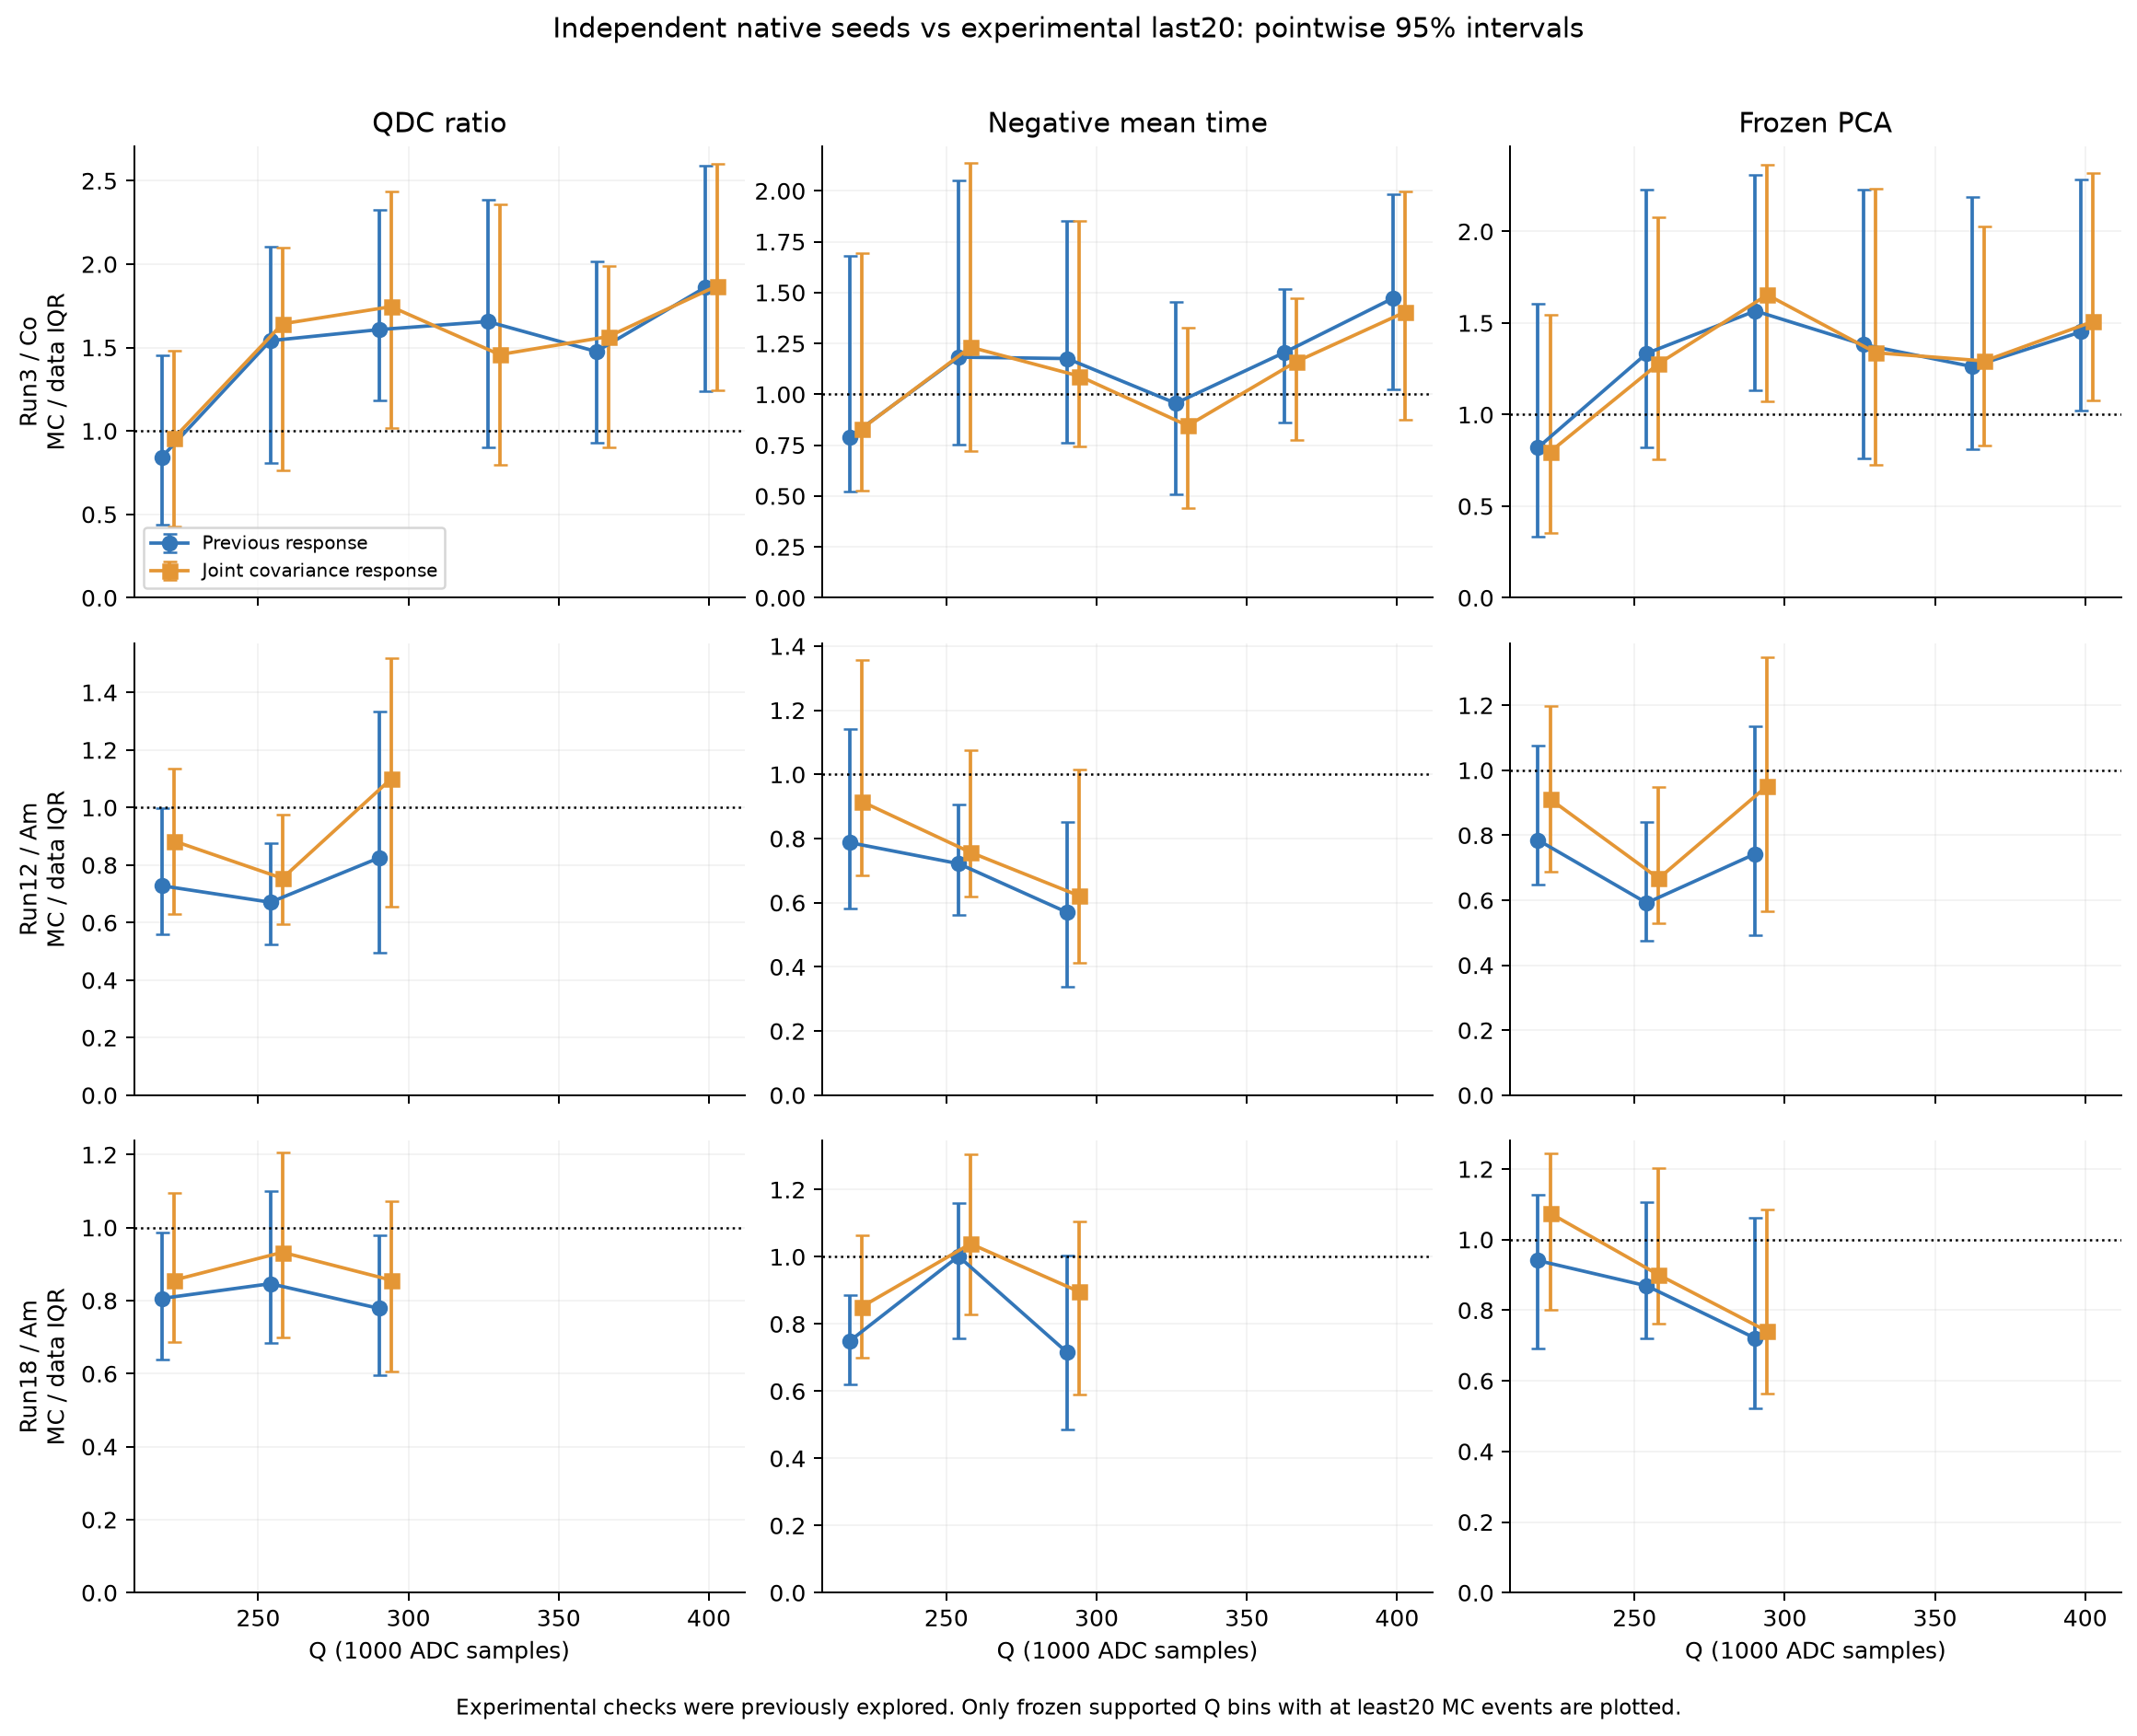

In [4]:
rows=[]
for run in [3,12,18]:
    for seg in ['first60','middle20','last20']:
        r=validation['checks'][f'run{run}_{seg}']
        for j,label in enumerate(labels):
            old=r['before']['IQR_ratio'][j]; new=r['after']['IQR_ratio'][j]
            lo,hi=r['after']['IQR_ratio_CI95'][j]['estimate95']
            rows.append([run,seg,label,f'{old:.3f}',f'{new:.3f}',f'[{lo:.3f}, {hi:.3f}]'])
display(Markdown(table(['run','实验段','方法','旧MC/实验','新MC/实验','新比值95%区间'],rows)))
display(Image(filename=str(OUT/'figures/pid_bandwidth_validation.png')))

|run|段|旧MC数|新MC数|旧均波形RMSE/峰|新均波形RMSE/峰|新MC/实测 F50,F102,F202|
|---|---|---|---|---|---|---|
|3|first60|256|255|1.04%|1.04%|1.024, 0.984, 0.996|
|3|last20|256|255|1.02%|1.02%|1.065, 1.021, 1.032|
|12|first60|356|352|0.95%|0.95%|1.002, 1.014, 1.022|
|12|last20|356|352|0.94%|0.92%|1.037, 1.034, 1.037|
|18|first60|359|356|0.86%|0.86%|0.992, 1.001, 0.994|
|18|last20|359|356|0.79%|0.80%|0.988, 0.996, 0.991|

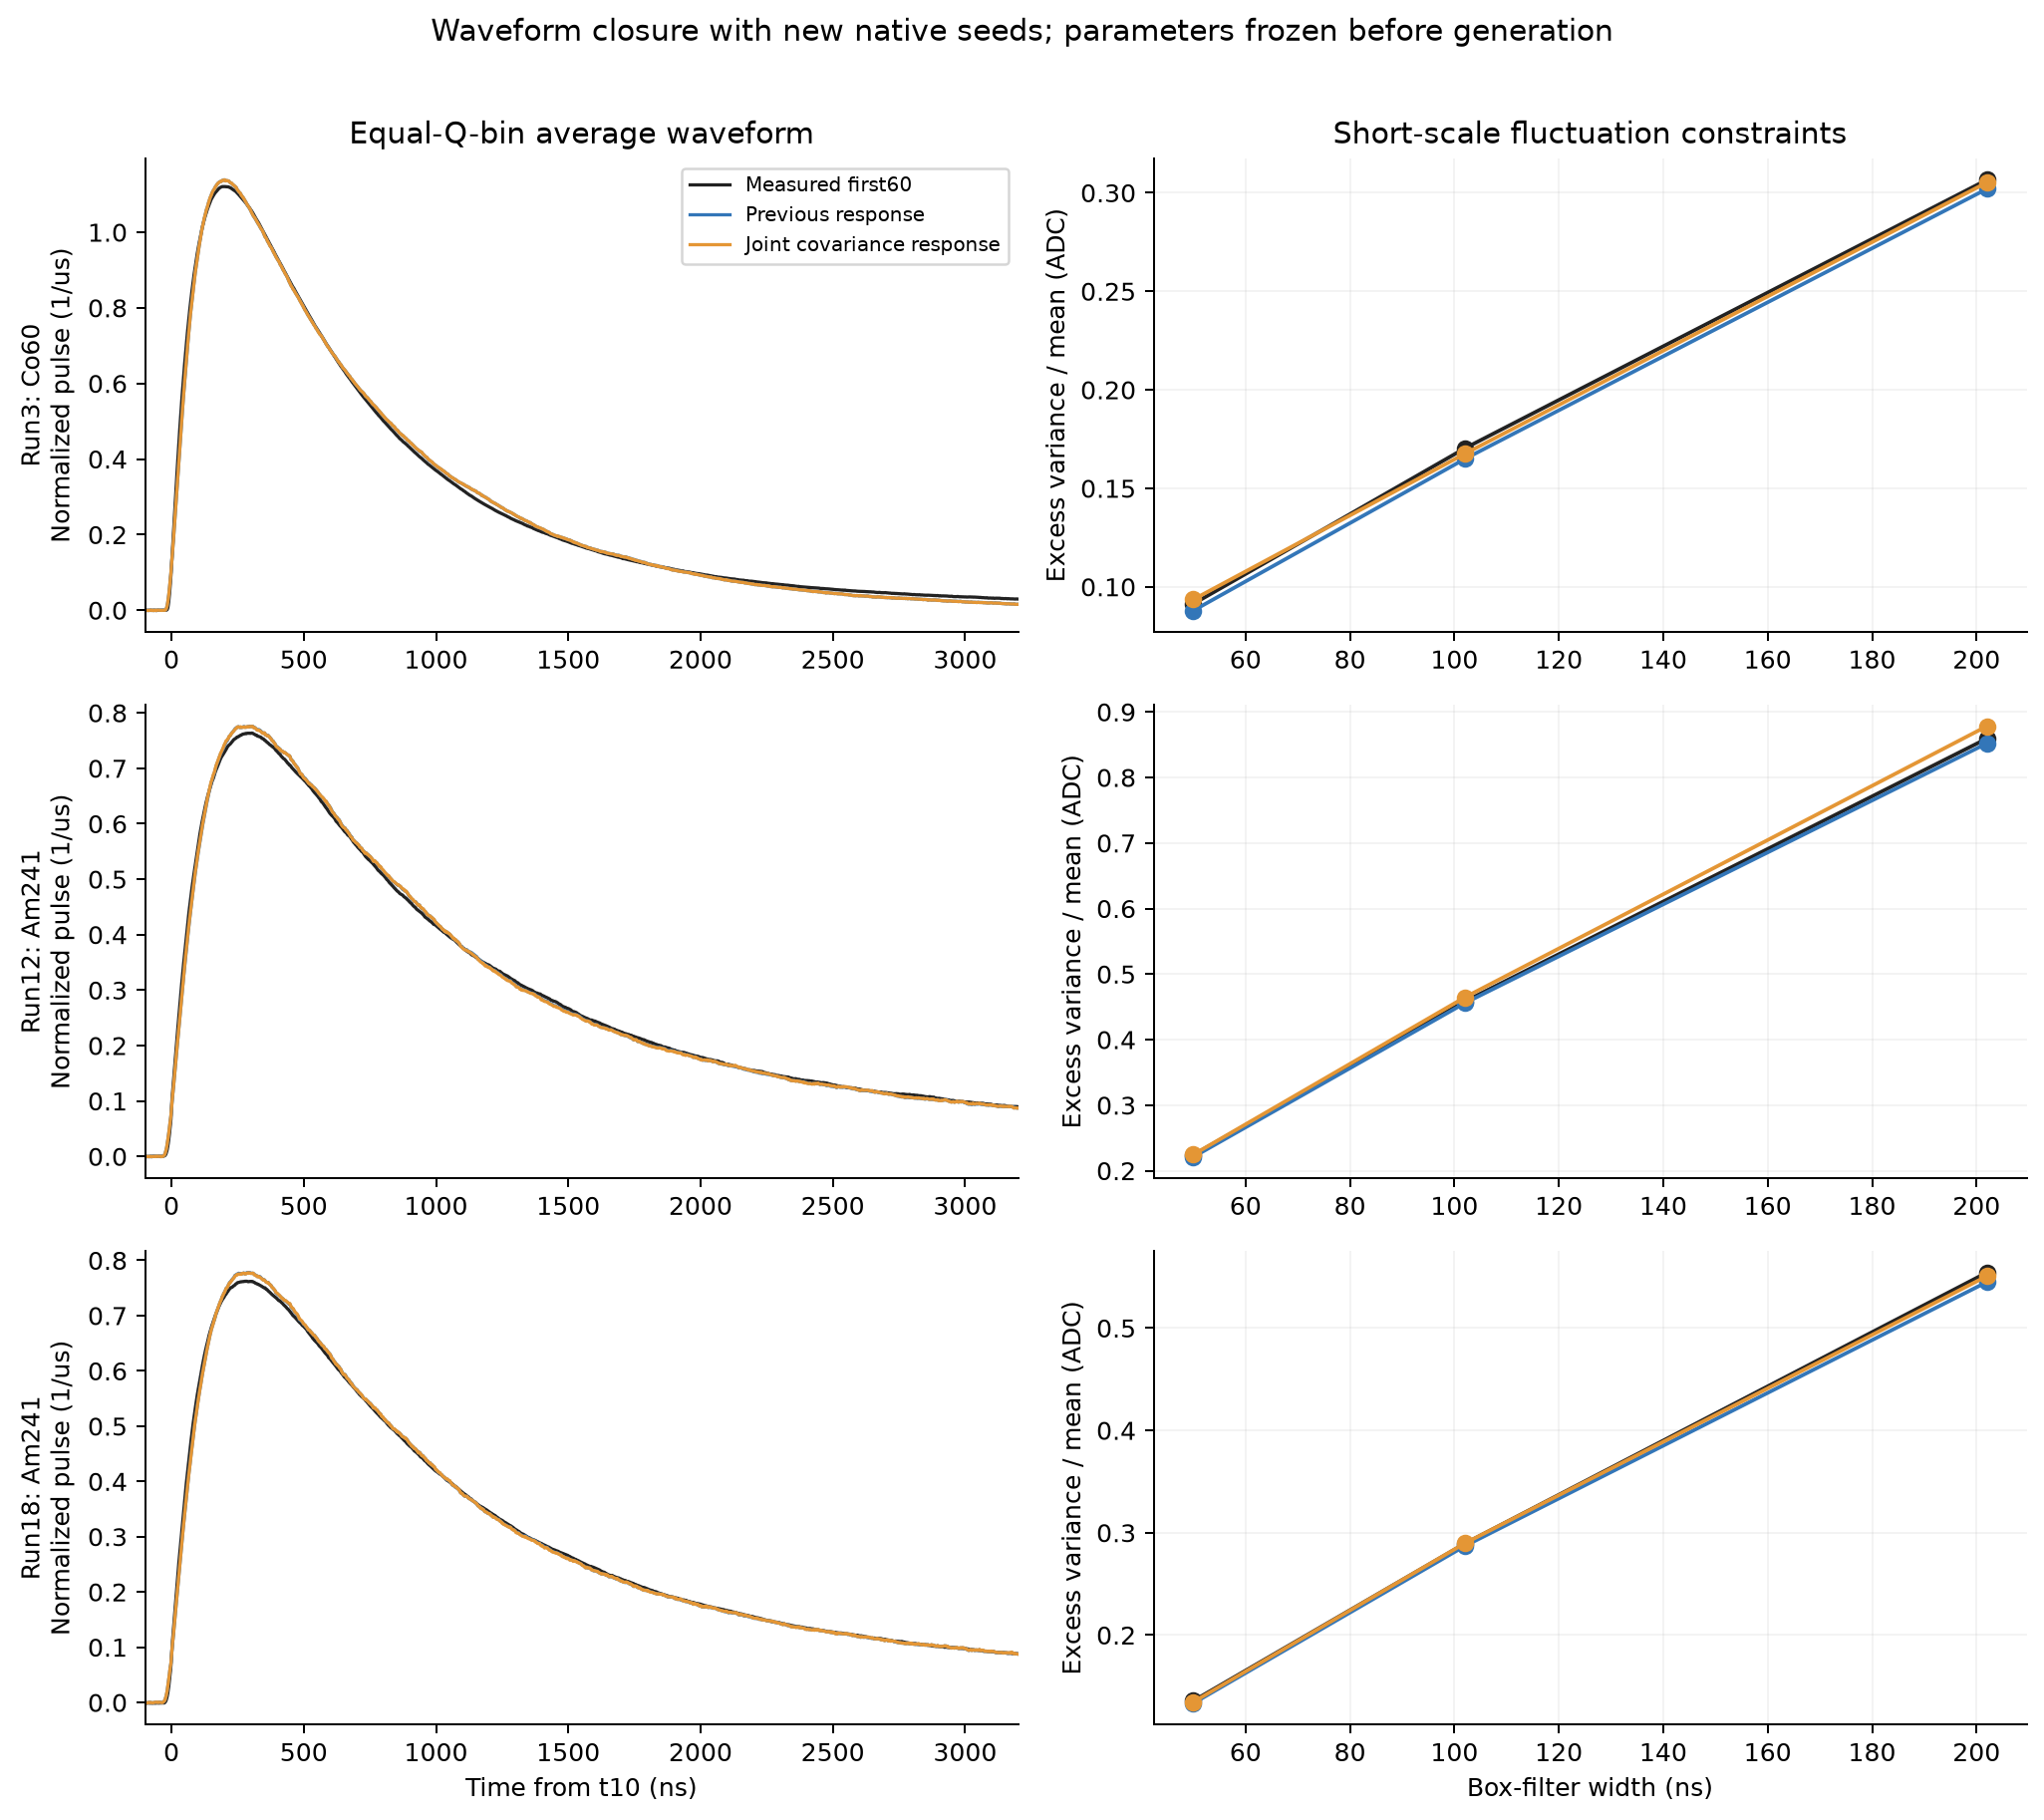

In [5]:
rows=[]
for run in [3,12,18]:
    for seg in ['first60','last20']:
        r=validation['checks'][f'run{run}_{seg}']
        rows.append([run,seg,r['before']['n_MC'],r['after']['n_MC'],
            f"{100*r['before']['mean_shape_normalized_RMSE']:.2f}%",f"{100*r['after']['mean_shape_normalized_RMSE']:.2f}%",
            ', '.join(f'{v:.3f}' for v in r['after']['F_ratio'])])
display(Markdown(table(['run','段','旧MC数','新MC数','旧均波形RMSE/峰','新均波形RMSE/峰','新MC/实测 F50,F102,F202'],rows)))
display(Image(filename=str(OUT/'figures/pid_width_waveform_closure.png')))

## 4. 对 PID 结论的影响

下表在**共同 run12 响应**下使用模拟沉积能量祖先真值（≥90%主导），固定上轮三个阈值和实验训练 PCA。
使用新母衰变全部合格波形检查，不用这些结果重新寻找95%接受率阈值。
改进带宽后，旧阈值的 α 接受比例可能改变；高 AUC 不能代替固定阈值的效率，也不能证明尾部泄漏为零。
模拟仍是条件结果，不能报告为实测 α 效率/γ 泄漏。


In [6]:
rows=[]
for j,m in enumerate(methods):
    r=validation['common_state_PID'][m]; op=r['operating']; a=op['alpha_acceptance']; g=op['gamma_leakage']
    rows.append([labels[j],f"{r['AUC']:.6f}",f"{a['passed']}/{a['total']}",f"{100*a['fraction']:.2f}%",
        f"{g['passed']}/{g['total']}",f"{100*g['one_sided95_upper']:.2f}%"])
display(Markdown(table(['方法','AUC','模拟α通过','接受比例','模拟γ进低分区','γ泄漏单侧95%上限'],rows)))
display(Markdown(decision['interpretation_zh']))

|方法|AUC|模拟α通过|接受比例|模拟γ进低分区|γ泄漏单侧95%上限|
|---|---|---|---|---|---|
|长短门比|1.000000|346/352|98.30%|0/260|1.15%|
|负平均时间|1.000000|339/352|96.31%|0/260|1.15%|
|冻结 PCA|1.000000|344/352|97.73%|0/260|1.15%|

**结论边界与后续处理：**

- 噪声关闭对照确认，在当前MC的QDC方差分解中，基线电子学项远小于原生信号与信号期残差；这不是直接测得实验中的因果占比。
- 改善来自信号期低频相关功率及积分协方差的约束，不是简单增加基线白噪声。模型能解释Am带宽缺口的一部分，不能据此唯一识别其电子学或材料来源。
- 新旧响应使用相同新光学历史。固定旧ID的QDC宽度变化：Co约0.992倍、run12 Am约1.185倍、run18 Am约1.088倍；因此Co没有实质改善，Am改善也不全由选择迁移造成。
- 平均波形归一化RMSE仍约峰值的0.8%–1.0%；最后20%三个短尺度涨落均值的新MC/实验比为约0.99–1.06。保持平均波形与短时起伏并不自动保证PID带宽完全匹配。
- 同一run12响应下两种源仍可分离，但有限样本零γ误判的单侧95%上限为1.15%，不是零泄漏；这些均为模拟条件性能。
- 不继续用本次验证段修改参数。下一轮应在原first60上联合约束有效光电子统计、读出传递函数和事件形状离散度；统一放大/缩小噪声不能同时处理Co偏宽与Am偏窄。只靠当前波形不能唯一确定光产额、PDE、实际负载和并联单元数。

## 5. 复现与边界

主要脚本位于 `simulation/`：`prepare_pid_bandwidth.py`、`diagnose_pid_bandwidth.py`、`fit_pid_bandwidth.py`、
`prepare_bandwidth_validation.py`、`analyze_bandwidth_validation.py`、`plot_pid_bandwidth.py`、`verify_pid_bandwidth.py`。
已冻结输出目录的准备/拟合步骤拒绝覆盖；如需重新运行，用新的研究目录，不能覆盖本轮或前轮记录。
`validation/protocol.json` 保存所有实际原生和重放命令、随机种子及配置哈希。
`record.json` 保存脚本快照、输入链和结果哈希；验证命令：

```bash
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 /home/xc/software/jupyter/.venv/bin/python simulation/verify_pid_bandwidth.py
```

几何、有效光产额/PDE/增益及并联网络仍有未确定的实验参数；4 µs波形对长衰减分量的约束有限。
当前改善只能支持“长时间相关的信号波动能解释部分带宽缺口”，不能区分电子学、增益起伏和发光形状起伏的全部物理来源。
下一步应依据本轮保留的残差，约束共同读出下的光电子统计与形状离散度；不能继续无条件增加白噪声。
